# Breakout Room #2 — La matriz cliente × producto y la similitud

**Objetivo:**
- Armar la matriz de compras (una fila por cliente, una columna por producto).
- Entender qué significa que dos clientes, o dos productos, "se parezcan" (similitud coseno).
- Ver con datos por qué la matriz es el corazón del filtrado colaborativo, y dónde falla.

Es la **base** del siguiente bloque: ahí usaremos esta matriz para recomendar. Donde dice **`# TODO`** hay algo para que ustedes completen.

> **Similitud coseno** entre dos vectores a y b: `a · b / (|a| × |b|)`. Va de 0 (no comparten nada) a 1 (idénticos).
> Con compras de sí/no, es *qué tanto se solapan* dos listas de compras, ajustado por su tamaño.

In [1]:
# En Google Colab no hace falta instalar nada extra.
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
VERDE, OSCURO, NARANJA, GRIS = "#00704A", "#11241C", "#C4512F", "#9A988E"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

orders = pd.read_csv("data/orders.csv", parse_dates=["order_date"])
items = pd.read_csv("data/items.csv")
customers = pd.read_csv("data/customers.csv")

# Escondemos los últimos 90 días: son el "examen" del último breakout. Hoy trabajamos solo con el pasado.
CUTOFF = orders["order_date"].max() - pd.Timedelta(days=90)
train = orders[orders["order_date"] <= CUTOFF]
print(f"Corte: {CUTOFF.date()} · {len(train):,} líneas de compra antes del corte")

Corte: 2026-06-01 · 19,087 líneas de compra antes del corte


## Paso 1 — la matriz

Una fila por cliente, una columna por producto. `1` = el cliente compró ese producto **al menos una vez** antes del corte.
Incluimos a los 2,000 clientes, aunque algunos no hayan comprado nada antes del corte.

In [2]:
M = (pd.crosstab(train["customer_id"], train["item"]) > 0).astype(int)
M = M.reindex(customers["customer_id"], fill_value=0)          # los 2,000 clientes
print("Forma de la matriz:", M.shape)
print(f"Densidad: {M.values.mean():.1%} de las celdas tienen un 1  →  {1 - M.values.mean():.1%} están vacías")
n_prod = M.sum(axis=1)
print(f"Productos distintos por cliente: promedio {n_prod.mean():.1f} · "
      f"con 0 productos: {(n_prod == 0).sum()} · con 1 solo: {(n_prod == 1).sum()}")
M.iloc[:6, :8]

Forma de la matriz: (2000, 29)
Densidad: 14.2% de las celdas tienen un 1  →  85.8% están vacías
Productos distintos por cliente: promedio 4.1 · con 0 productos: 268 · con 1 solo: 63


item,Agua,Americano,Bagel,Banana Bread,Brownie,Cappuccino,Chocolate Caliente,Cold Brew
customer_id,,,,,,,,
1,1,0,0,1,0,0,1,0
2,1,0,0,0,0,0,0,1
3,1,0,0,0,0,0,0,0
4,1,0,0,0,0,0,1,0
5,1,0,0,0,0,0,0,0
6,1,1,1,0,0,0,0,0


## Paso 2 — similitud entre dos clientes (a mano)

Tomamos tres clientes: **A = 14**, **B = 1015** y **C = 62**. Primero miren qué compró cada uno, y adivinen
quién se parece a quién *antes* de calcular nada.

In [3]:
ID_A, ID_B, ID_C = 14, 1015, 62
for cid in (ID_A, ID_B, ID_C):
    print(f"Cliente {cid:>4}:", ", ".join(M.columns[M.loc[cid] == 1]))

Cliente   14: Agua, Banana Bread, Cappuccino, Flat White, Muffin, Té Chai
Cliente 1015: Agua, Banana Bread, Cappuccino, Latte, Muffin, Té Chai
Cliente   62: Brownie, Cold Brew, Ensalada, Granola, Matcha Latte


In [4]:
a, b_, c = M.loc[ID_A].values, M.loc[ID_B].values, M.loc[ID_C].values

# TODO 1: completen la función coseno(x, y) = (x · y) / (|x| × |y|).
# Pistas: np.dot(x, y) para el producto punto; np.linalg.norm(x) para la longitud del vector.
def coseno(x, y):
    return np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))


print(f"sim(A, B) = {coseno(a, b_):.3f}")
print(f"sim(A, C) = {coseno(a, c):.3f}")
print("Revisión con scikit-learn:", cosine_similarity([a], [b_])[0, 0].round(3), cosine_similarity([a], [c])[0, 0].round(3))

sim(A, B) = 0.833
sim(A, C) = 0.000
Revisión con scikit-learn: 0.833 0.0


## Paso 3 — la misma idea, pero entre productos

Los productos también tienen "vector": la **columna** de la matriz (qué clientes lo compraron). Calculen la similitud entre
**Latte y Croissant**, y entre **Latte y Ensalada**.

In [5]:
latte, croissant, ensalada = M["Latte"].values, M["Croissant"].values, M["Ensalada"].values

# TODO 2: calculen la similitud coseno entre las columnas, usando SU función coseno() del Paso 2.
sim_latte_croissant = coseno(latte, croissant)
sim_latte_ensalada  = coseno(latte, ensalada)

print(f"sim(Latte, Croissant) = {sim_latte_croissant:.3f}")
print(f"sim(Latte, Ensalada)  = {sim_latte_ensalada:.3f}")

sim(Latte, Croissant) = 0.505
sim(Latte, Ensalada)  = 0.060


## Paso 4 — todas las similitudes, de una vez

Con `cosine_similarity` calculamos todas las parejas de productos (29 × 29). Ordenamos los productos por "familia de gusto"
para que se vea si hay estructura.

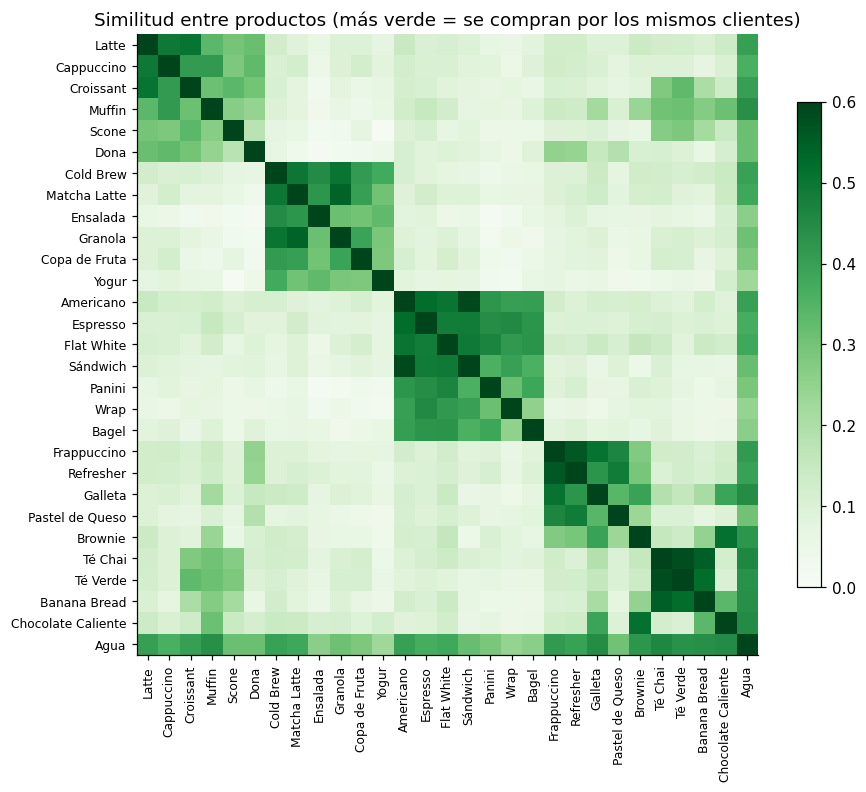

In [6]:
orden = ["Latte", "Cappuccino", "Croissant", "Muffin", "Scone", "Dona",
         "Cold Brew", "Matcha Latte", "Ensalada", "Granola", "Copa de Fruta", "Yogur",
         "Americano", "Espresso", "Flat White", "Sándwich", "Panini", "Wrap", "Bagel",
         "Frappuccino", "Refresher", "Galleta", "Pastel de Queso", "Brownie",
         "Té Chai", "Té Verde", "Banana Bread", "Chocolate Caliente", "Agua"]
S_item = pd.DataFrame(cosine_similarity(M[orden].values.T), index=orden, columns=orden)

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(S_item.values, cmap="Greens", vmin=0, vmax=0.6)
ax.set_xticks(range(len(orden))); ax.set_xticklabels(orden, rotation=90, fontsize=8)
ax.set_yticks(range(len(orden))); ax.set_yticklabels(orden, fontsize=8)
ax.set_title("Similitud entre productos (más verde = se compran por los mismos clientes)")
plt.colorbar(im, shrink=0.7); plt.tight_layout(); plt.show()

**Para discutir:**

1. ¿Qué bloques se ven en la gráfica y qué tipo de clientes representan?
La gráfica muestra varios bloques verdes que corresponden a grupos de productos que suelen ser comprados por los mismos tipos de clientes. Un bloque claro es el de bebidas de café (Latte, Cappuccino, Flat White, Americano, Espresso), que representa a clientes que van por café tradicional. Otro bloque es el de panadería dulce (Croissant, Muffin, Scone, Dona, Galleta, Brownie), que refleja a quienes acompañan su bebida con un postre o snack. También aparece un bloque de opciones “saludables” como Ensalada, Granola, Yogur y Copa de Fruta, que agrupa a clientes con preferencias más ligeras. Finalmente, hay un bloque de bebidas frías y refrescos (Frappuccino, Refresher, Té Verde, Té Chai), que suele corresponder a clientes que buscan alternativas al café caliente. Cada bloque representa un patrón de compra coherente dentro de un tipo de consumidor.

2. ¿Qué pasa con la fila y columna del Agua y por qué?
La fila y columna del Agua aparecen con valores relativamente altos frente a casi todos los productos, formando un patrón verde uniforme. Esto ocurre porque Agua es un producto extremadamente común: prácticamente todos los clientes la compran en algún momento, sin importar qué más lleven. En términos de similitud coseno, esto genera solapamientos altos con cualquier otro vector de compras, no porque Agua sea complementaria, sino porque su presencia es masiva. Esto conecta directamente con el análisis del breakout anterior: cuando un producto se compra casi siempre, su similitud, confianza y soporte tienden a ser altos, pero su lift no indica complementariedad real. En resumen, Agua se parece a todo porque todos la compran.

## Paso 5 — el cliente sin historia

La matriz solo sabe lo que los clientes ya compraron. Veamos a quién no le sirve.

0    0.134
1    0.032
2    0.096
3    0.155
4    0.164
5    0.420


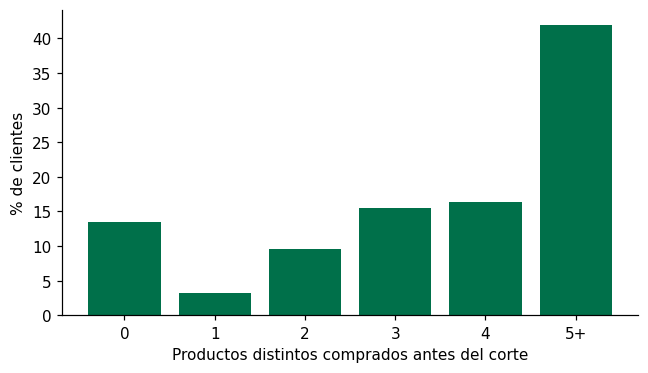

In [7]:
dist = n_prod.clip(upper=5).value_counts().sort_index()
print((dist / len(M)).rename("% de clientes").round(3).to_string())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(dist.index.astype(str).str.replace("5", "5+"), dist.values / len(M) * 100, color=VERDE)
ax.set_xlabel("Productos distintos comprados antes del corte"); ax.set_ylabel("% de clientes")
plt.tight_layout(); plt.show()

3. ¿A cuántos clientes les sirve poco o nada la similitud (0 o 1 producto)? ¿Qué le recomendarían a un cliente con 0 productos?
4. Ahora que ven la matriz, ¿qué le pasa a la similitud si el catálogo tuviera 10,000 productos y 2 millones de clientes? (Lo retomamos en el siguiente breakout.)

A los clientes que han comprado 0 o 1 producto antes del corte la similitud les sirve muy poco o nada, porque no hay suficiente información para comparar patrones de compra: con 0 productos no existe vector de compras útil, y con 1 producto solo sabemos que compraron “algo” pero no cómo combinan productos. A un cliente con 0 productos, la recomendación no debería basarse en similitud, sino en reglas generales: destacar los productos más populares, las ofertas de entrada (combos básicos café + pan), o recomendaciones editoriales del local, hasta que empiece a generar historial de compra que permita usar similitud de manera significativa.

Si el catálogo creciera a 10,000 productos y hubiera 2 millones de clientes, la matriz de similitud se volvería enorme y muy dispersa: la mayoría de productos se comprarían por pocos clientes y compartirían muy poco solapamiento entre sí, generando muchas similitudes cercanas a 0. Además, el cálculo completo sería muy costoso computacionalmente (10,000 × 10,000 pares), y la interpretación se volvería difícil sin técnicas de reducción de dimensión o filtrado. En ese escenario, la similitud coseno seguiría siendo útil, pero habría que combinarla con métodos más escalables (modelos de recomendación, embeddings, clustering) para manejar la alta dimensionalidad y la enorme cantidad de clientes.